In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline
pd.set_option('display.max_columns', None)

In [13]:
ruta = r"C:\Users\MartínPazYáñez\Desktop\iron\bootcamp\Module 3\lab-eda-univariate\amz_uk_price_prediction_dataset.csv"
df = pd.read_csv(ruta)

df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


Part 1: Analyzing Best-Seller Trends Across Product Categories
Objective: Understand the relationship between product categories and their best-seller status.

Crosstab Analysis:

Create a crosstab between the product category and the isBestSeller status.

Are there categories where being a best-seller is more prevalent?

Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.

In [14]:
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])

crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [15]:
# Step 1: Get the count of best-sellers (where best_seller = 1) for each category
# If column 1 doesn't exist, create a column of zeros
best_seller_counts = crosstab_result.get(1, pd.Series(0, index=crosstab_result.index))

# Step 2: Calculate what percentage of products are best-sellers in each category
# We divide best-sellers by total products in that category
total_products_per_category = crosstab_result.sum(axis=1)
crosstab_result['best_seller_proportion'] = best_seller_counts / total_products_per_category

# Step 3: Sort categories from highest to lowest best-seller percentage
sorted_crosstab = crosstab_result.sort_values(by='best_seller_proportion', ascending=False)

# Show the result
sorted_crosstab

isBestSeller,False,True,best_seller_proportion
category,,,
3D Printers,247,1,0.0
3D Printing & Scanning,4065,2,0.0
Abrasive & Finishing Products,245,5,0.0
Action Cameras,1696,1,0.0
Adapters,251,3,0.0
...,...,...,...
Wind Instruments,243,7,0.0
Window Treatments,234,5,0.0
Women,17559,213,0.0


Statistical Tests:

Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
Compute Cramér's V to understand the strength of association between best-seller status and category.

In [16]:
from scipy.stats import chi2_contingency

# Chi-square test for 'MSZoning' and 'SaleCondition'
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)

chi2_statistic, chi2_p_value

ValueError: The internally computed table of expected frequencies has a zero element at (np.int64(0), np.int64(2)).

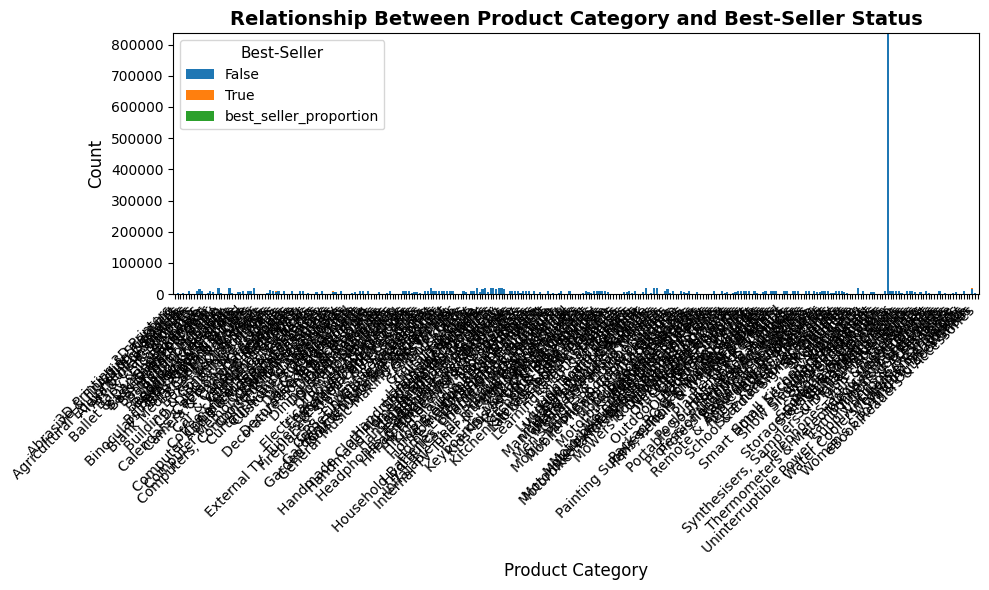

In [ ]:
import matplotlib.pyplot as plt

# Plot
fig, ax = plt.subplots(figsize=(10, 6))

crosstab_result.plot(
    kind='bar',
    stacked=True,
    ax=ax,
    width=0.8
)

ax.set_title('Relationship Between Product Category and Best-Seller Status', fontsize=14, fontweight='bold')
ax.set_xlabel('Product Category', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.legend(title='Best-Seller', fontsize=10, title_fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.show()


Statistical Tests:

Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
Compute Cramér's V to understand the strength of association between best-seller status and category.
Visualizations:

Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

In [ ]:
# Crosstab between category and isBestSeller
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])
crosstab_result


isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [ ]:
from scipy.stats import chi2_contingency

chi2_statistic, p_value, dof, expected = chi2_contingency(crosstab_result)

print("Chi-square statistic:", chi2_statistic)
print("Degrees of freedom:", dof)
print("p-value:", p_value)


Chi-square statistic: 36540.20270061387
Degrees of freedom: 295
p-value: 0.0


In [ ]:
import numpy as np
from scipy.stats.contingency import association

# Option 1: Using scipy's association (simplest)
cramers_v = association(crosstab_result, method='cramer')
print("Cramér's V:", cramers_v)


Cramér's V: 0.1222829439760564


In [ ]:
df.columns


Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

Part 2: Exploring Product Prices and Ratings Across Categories and Brands
Objective: Investigate how different product categories influence product prices.

Preliminary Step: Remove outliers in product prices.

For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

Violin Plots:

Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
Which product category tends to have the highest median price? Don't filter here by top categories.
Bar Charts:

Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
Which product category commands the highest average price? Don't filter here by top categories.
Box Plots:

Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

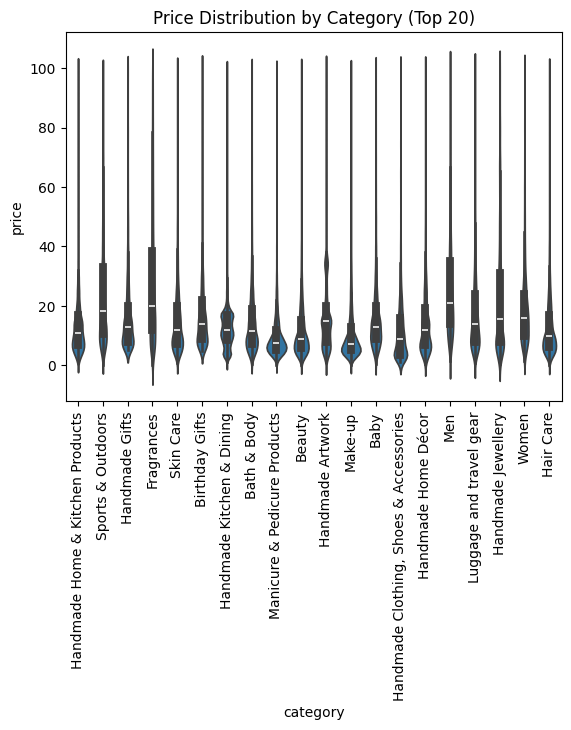

Category with the highest median price: Desktop PCs


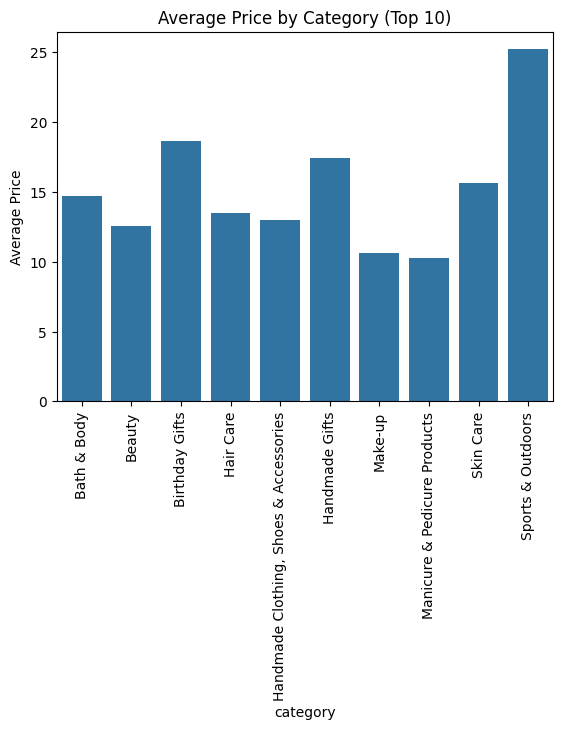

Category with the highest average price: Motherboards


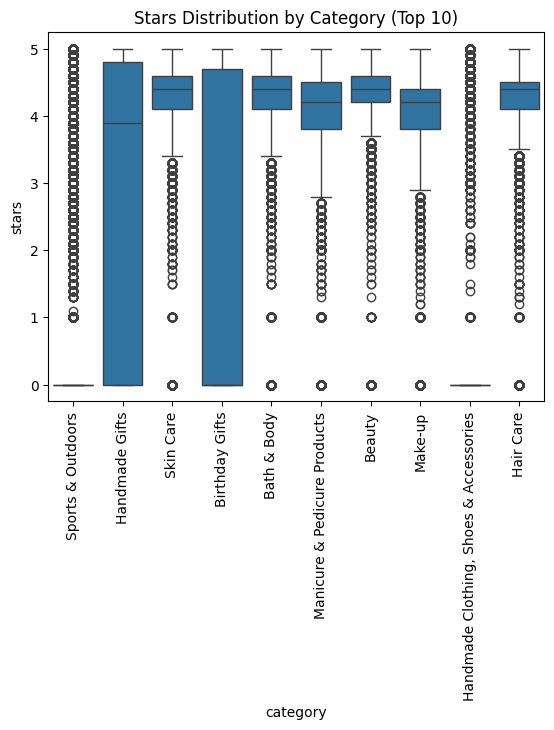

Category with the highest median stars: Computer Memory


In [17]:
# 1. Remove price outliers using the IQR (Tukey's method)

def remove_outliers_iqr(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    mask = (series >= lower_bound) & (series <= upper_bound)
    return mask

price_mask = remove_outliers_iqr(df['price'])
df_no_out = df[price_mask]


# 2. Violin plot: price distribution across categories (Top 20 by count)

category_counts = df_no_out['category'].value_counts()
top20_categories = category_counts.index[:20]

df_top20 = df_no_out[df_no_out['category'].isin(top20_categories)]

sns.violinplot(data=df_top20, x='category', y='price')
plt.xticks(rotation=90)
plt.title("Price Distribution by Category (Top 20)")
plt.show()

median_price = df_no_out.groupby('category')['price'].median().sort_values(ascending=False)
print("Category with the highest median price:", median_price.index[0])


# 3. Bar chart: average price for the top 10 categories (by count)

top10_categories = category_counts.index[:10]
df_top10 = df_no_out[df_no_out['category'].isin(top10_categories)]

avg_price_top10 = df_top10.groupby('category')['price'].mean()

sns.barplot(x=avg_price_top10.index, y=avg_price_top10.values)
plt.xticks(rotation=90)
plt.title("Average Price by Category (Top 10)")
plt.ylabel("Average Price")
plt.show()

avg_price = df_no_out.groupby('category')['price'].mean().sort_values(ascending=False)
print("Category with the highest average price:", avg_price.index[0])


# 4. Box plots: stars (ratings) distribution across categories (Top 10 by count)

top10_rating_categories = category_counts.index[:10]
df_rating_top10 = df_no_out[df_no_out['category'].isin(top10_rating_categories)]

sns.boxplot(data=df_rating_top10, x='category', y='stars')
plt.xticks(rotation=90)
plt.title("Stars Distribution by Category (Top 10)")
plt.show()

median_stars = df_no_out.groupby('category')['stars'].median().sort_values(ascending=False)
print("Category with the highest median stars:", median_stars.index[0])


art 3: Investigating the Interplay Between Product Prices and Ratings
Objective: Analyze how product ratings (stars) correlate with product prices.

Correlation Coefficients:

Calculate the correlation coefficient between price and stars.
Is there a significant correlation between product price and its rating?
Visualizations:

Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
Use a correlation heatmap to visualize correlations between all numerical variables.
Examine if product prices typically follow a normal distribution using a QQ plot.


Correlation (Pearson) between price and stars: -0.07767299878181444
Pearson r: -0.07767299878181314
p-value: 0.0


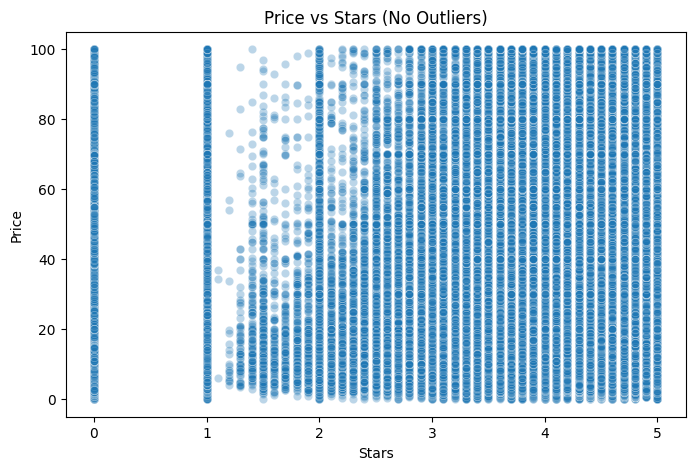

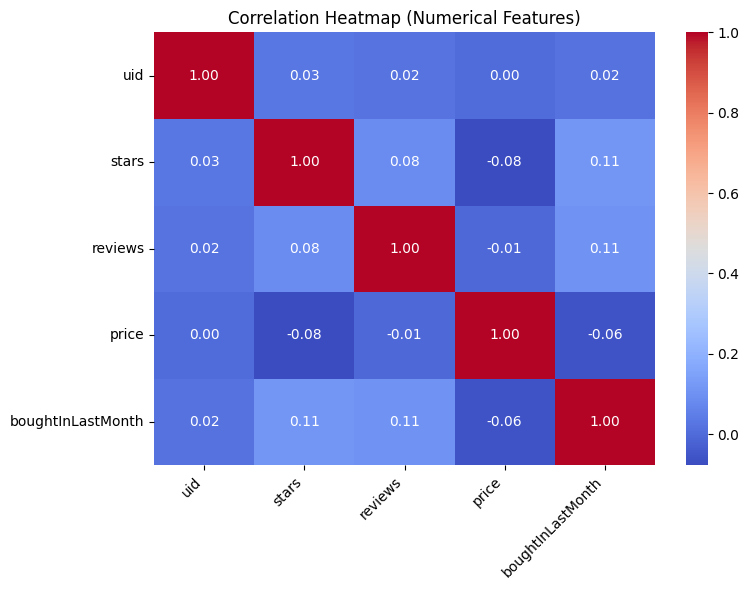

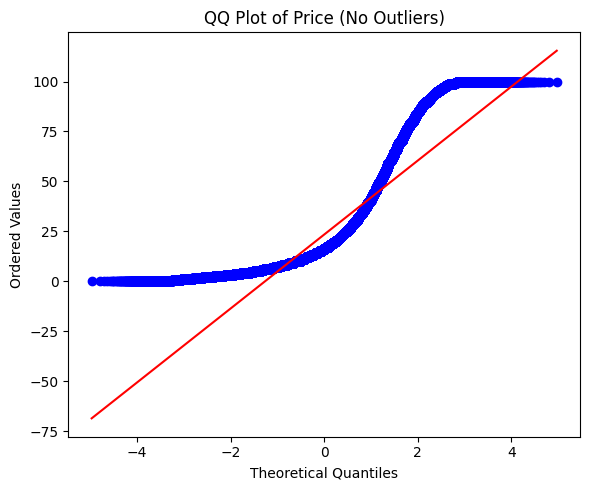

In [18]:
# 1. Correlation between price and stars (after removing outliers)

corr_price_stars = df_no_out['price'].corr(df_no_out['stars'])
print("Correlation (Pearson) between price and stars:", corr_price_stars)

pearson_r, p_value = pearsonr(df_no_out['price'], df_no_out['stars'])
print("Pearson r:", pearson_r)
print("p-value:", p_value)


# 2. Scatter plot: relationship between price and stars

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_no_out, x='stars', y='price', alpha=0.3)
plt.title("Price vs Stars (No Outliers)")
plt.xlabel("Stars")
plt.ylabel("Price")
plt.show()


# 3. Correlation heatmap for all numerical variables

numeric_df = df_no_out.select_dtypes(include='number')
corr_matrix = numeric_df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap (Numerical Features)")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


# 4. QQ plot: checking if price follows a normal distribution

plt.figure(figsize=(6, 5))
stats.probplot(df_no_out['price'], dist="norm", plot=plt)
plt.title("QQ Plot of Price (No Outliers)")
plt.xlabel("Theoretical Quantiles")
plt.ylabel("Ordered Values")
plt.tight_layout()
plt.show()